# Arvores de Regressão

In [ ]:
# instalação de pacotes

%pip install pandas
%pip install numpy
%pip install scikit-learn

In [10]:
# imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import plot_tree
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from pathlib import Path
from urllib.request import urlretrieve

# Importando o dataset

In [11]:
## Baixando o dataset

url = "https://raw.githubusercontent.com/vqrca/ml-datasets/refs/heads/main/amazon_delivery.csv"
filename = "amazon_delivery.csv"

def download_dataset(url:str, filename:str) -> None:
    """Download the dataset from the given URL and save it to the specified filename."""
    if Path(filename).exists():
        print(f"Dataset already exists as {filename}. Skipping download.")
        return
    urlretrieve(url, filename)
    print(f"Dataset downloaded and saved as {filename}")

download_dataset(url, filename)

Dataset downloaded and saved as amazon_delivery.csv


# Utils

In [20]:
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0  # Raio médio da Terra em quilômetros
    lat1, lon1, lat2, lon2 = map(
        np.radians,
        [lat1, lon1, lat2, lon2]
    )
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )
    return 2 * R * np.arcsin(np.sqrt(a))

# Manipulando o dataset

In [17]:
df = pd.read_csv(filename)

pd.set_option('display.max_columns', None)
display(df.head())
display(df.shape)
display(df.info())
display(df.describe())

,Order_ID,Agent_Age,Agent_Rating,Store_Latitude,Store_Longitude,Drop_Latitude,Drop_Longitude,Order_Date,Order_Time,Pickup_Time,Weather,Traffic,Vehicle,Area,Delivery_Time,Category
0,ialx566343618,37,4.9,22.745049,75.892471,22.765049,75.912471,2022-03-19,11:30:00,11:45:00,Sunny,High,motorcycle,Urban,120,Clothing
1,akqg208421122,34,4.5,12.913041,77.683237,13.043041,77.813237,2022-03-25,19:45:00,19:50:00,Stormy,Jam,scooter,Metropolitian,165,Electronics
2,njpu434582536,23,4.4,12.914264,77.678400,12.924264,77.688400,2022-03-19,08:30:00,08:45:00,Sandstorms,Low,motorcycle,Urban,130,Sports
3,rjto796129700,38,4.7,11.003669,76.976494,11.053669,77.026494,2022-04-05,18:00:00,18:10:00,Sunny,Medium,motorcycle,Metropolitian,105,Cosmetics
4,zguw716275638,32,4.6,12.972793,80.249982,13.012793,80.289982,2022-03-26,13:30:00,13:45:00,Cloudy,High,scooter,Metropolitian,150,Toys


(43739, 16)

<class 'pandas.DataFrame'>
RangeIndex: 43739 entries, 0 to 43738
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order_ID         43739 non-null  str    
 1   Agent_Age        43739 non-null  int64  
 2   Agent_Rating     43685 non-null  float64
 3   Store_Latitude   43739 non-null  float64
 4   Store_Longitude  43739 non-null  float64
 5   Drop_Latitude    43739 non-null  float64
 6   Drop_Longitude   43739 non-null  float64
 7   Order_Date       43739 non-null  str    
 8   Order_Time       43739 non-null  str    
 9   Pickup_Time      43739 non-null  str    
 10  Weather          43648 non-null  str    
 11  Traffic          43739 non-null  str    
 12  Vehicle          43739 non-null  str    
 13  Area             43739 non-null  str    
 14  Delivery_Time    43739 non-null  int64  
 15  Category         43739 non-null  str    
dtypes: float64(5), int64(2), str(9)
memory usage: 5.3 MB


None

,Agent_Age,Agent_Rating,Store_Latitude,Store_Longitude,Drop_Latitude,Drop_Longitude,Delivery_Time
count,43739.000000,43685.000000,43739.000000,43739.000000,43739.000000,43739.000000,43739.000000
mean,29.567137,4.633780,17.210960,70.661177,17.459031,70.821842,124.905645
std,5.815155,0.334716,7.764225,21.475005,7.342950,21.153148,51.915451
min,15.000000,1.000000,-30.902872,-88.366217,0.010000,0.010000,10.000000
25%,25.000000,4.500000,12.933298,73.170283,12.985996,73.280000,90.000000
50%,30.000000,4.700000,18.551440,75.898497,18.633626,76.002574,125.000000
75%,35.000000,4.900000,22.732225,78.045359,22.785049,78.104095,160.000000
max,50.000000,6.000000,30.914057,88.433452,31.054057,88.563452,270.000000


In [29]:
# filtrando os dados, limpando as coordenadas geográficas e removendo valores nulos

lat_min, lat_max = 6.0, 38.0
lon_min, lon_max = 67.0, 98.0

filtro = (
    df['Store_Latitude'].between(lat_min, lat_max)
    & df['Store_Longitude'].between(lon_min, lon_max)
    & df['Drop_Latitude'].between(lat_min, lat_max)
    & df['Drop_Longitude'].between(lon_min, lon_max)
    & df['Agent_Rating'].between(1.0, 5.0)
    & df['Agent_Rating'].notna()
    & df['Weather'].notna()
)

df_limpo = df[filtro].copy()
display(df_limpo.head())
display(df_limpo.shape)
display(df_limpo.info())
display(df_limpo.describe())

,Order_ID,Agent_Age,Agent_Rating,Store_Latitude,Store_Longitude,Drop_Latitude,Drop_Longitude,Order_Date,Order_Time,Pickup_Time,Weather,Traffic,Vehicle,Area,Delivery_Time,Category
0,ialx566343618,37,4.9,22.745049,75.892471,22.765049,75.912471,2022-03-19,11:30:00,11:45:00,Sunny,High,motorcycle,Urban,120,Clothing
1,akqg208421122,34,4.5,12.913041,77.683237,13.043041,77.813237,2022-03-25,19:45:00,19:50:00,Stormy,Jam,scooter,Metropolitian,165,Electronics
2,njpu434582536,23,4.4,12.914264,77.678400,12.924264,77.688400,2022-03-19,08:30:00,08:45:00,Sandstorms,Low,motorcycle,Urban,130,Sports
3,rjto796129700,38,4.7,11.003669,76.976494,11.053669,77.026494,2022-04-05,18:00:00,18:10:00,Sunny,Medium,motorcycle,Metropolitian,105,Cosmetics
4,zguw716275638,32,4.6,12.972793,80.249982,13.012793,80.289982,2022-03-26,13:30:00,13:45:00,Cloudy,High,scooter,Metropolitian,150,Toys


(39958, 16)

<class 'pandas.DataFrame'>
Index: 39958 entries, 0 to 43738
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order_ID         39958 non-null  str    
 1   Agent_Age        39958 non-null  int64  
 2   Agent_Rating     39958 non-null  float64
 3   Store_Latitude   39958 non-null  float64
 4   Store_Longitude  39958 non-null  float64
 5   Drop_Latitude    39958 non-null  float64
 6   Drop_Longitude   39958 non-null  float64
 7   Order_Date       39958 non-null  str    
 8   Order_Time       39958 non-null  str    
 9   Pickup_Time      39958 non-null  str    
 10  Weather          39958 non-null  str    
 11  Traffic          39958 non-null  str    
 12  Vehicle          39958 non-null  str    
 13  Area             39958 non-null  str    
 14  Delivery_Time    39958 non-null  int64  
 15  Category         39958 non-null  str    
dtypes: float64(5), int64(2), str(9)
memory usage: 5.2 MB


None

,Agent_Age,Agent_Rating,Store_Latitude,Store_Longitude,Drop_Latitude,Drop_Longitude,Delivery_Time
count,39958.000000,39958.000000,39958.000000,39958.000000,39958.000000,39958.000000,39958.000000
mean,29.554332,4.634003,18.897525,76.909839,18.961162,76.973475,125.107338
std,5.761347,0.314920,5.463903,3.489784,5.465724,3.490006,51.946315
min,20.000000,2.500000,9.957144,72.768726,9.967144,72.778726,10.000000
25%,25.000000,4.500000,12.986047,73.897902,13.065479,73.939315,90.000000
50%,30.000000,4.700000,19.065838,76.618203,19.115838,76.662278,125.000000
75%,35.000000,4.900000,22.751234,78.347554,22.818060,78.399645,160.000000
max,39.000000,5.000000,30.914057,88.433452,31.054057,88.563452,270.000000


In [30]:
# gerando a distância entre a loja e o ponto de entrega usando a fórmula de Haversine

df_limpo['Distance_km'] = haversine_km(
    df_limpo['Store_Latitude'],
    df_limpo['Store_Longitude'],
    df_limpo['Drop_Latitude'],
    df_limpo['Drop_Longitude']
)
display(df_limpo.head())

,Order_ID,Agent_Age,Agent_Rating,Store_Latitude,Store_Longitude,Drop_Latitude,Drop_Longitude,Order_Date,Order_Time,Pickup_Time,Weather,Traffic,Vehicle,Area,Delivery_Time,Category,Distance_km
0,ialx566343618,37,4.9,22.745049,75.892471,22.765049,75.912471,2022-03-19,11:30:00,11:45:00,Sunny,High,motorcycle,Urban,120,Clothing,3.025149
1,akqg208421122,34,4.5,12.913041,77.683237,13.043041,77.813237,2022-03-25,19:45:00,19:50:00,Stormy,Jam,scooter,Metropolitian,165,Electronics,20.183530
2,njpu434582536,23,4.4,12.914264,77.678400,12.924264,77.688400,2022-03-19,08:30:00,08:45:00,Sandstorms,Low,motorcycle,Urban,130,Sports,1.552758
3,rjto796129700,38,4.7,11.003669,76.976494,11.053669,77.026494,2022-04-05,18:00:00,18:10:00,Sunny,Medium,motorcycle,Metropolitian,105,Cosmetics,7.790401
4,zguw716275638,32,4.6,12.972793,80.249982,13.012793,80.289982,2022-03-26,13:30:00,13:45:00,Cloudy,High,scooter,Metropolitian,150,Toys,6.210138


In [31]:
# convertendo as colunas de tempo para o tipo datetime

df_limpo['Order_Time'] = pd.to_datetime(
    df_limpo['Order_Time'], 
    format='%H:%M:%S', 
    errors='coerce'
    )

df_limpo['Pickup_Time'] = pd.to_datetime(
    df_limpo['Pickup_Time'], 
    format='%H:%M:%S', 
    errors='coerce'
    )

# calculando o intervalo de tempo entre o pedido e a coleta em minutos
df_limpo['Tempo_Preparo_min'] = (
    (df_limpo['Pickup_Time'] - df_limpo['Order_Time'])
).dt.total_seconds() / 60

# corrigindo intervalos que passam da meia noite
df_limpo.loc[
    df_limpo['Tempo_Preparo_min'] < 0, 'Tempo_Preparo_min'
] += 24 * 60

display(df_limpo.head())

,Order_ID,Agent_Age,Agent_Rating,Store_Latitude,Store_Longitude,Drop_Latitude,Drop_Longitude,Order_Date,Order_Time,Pickup_Time,Weather,Traffic,Vehicle,Area,Delivery_Time,Category,Distance_km,Tempo_Preparo_min
0,ialx566343618,37,4.9,22.745049,75.892471,22.765049,75.912471,2022-03-19,1900-01-01 11:30:00,1900-01-01 11:45:00,Sunny,High,motorcycle,Urban,120,Clothing,3.025149,15.0
1,akqg208421122,34,4.5,12.913041,77.683237,13.043041,77.813237,2022-03-25,1900-01-01 19:45:00,1900-01-01 19:50:00,Stormy,Jam,scooter,Metropolitian,165,Electronics,20.183530,5.0
2,njpu434582536,23,4.4,12.914264,77.678400,12.924264,77.688400,2022-03-19,1900-01-01 08:30:00,1900-01-01 08:45:00,Sandstorms,Low,motorcycle,Urban,130,Sports,1.552758,15.0
3,rjto796129700,38,4.7,11.003669,76.976494,11.053669,77.026494,2022-04-05,1900-01-01 18:00:00,1900-01-01 18:10:00,Sunny,Medium,motorcycle,Metropolitian,105,Cosmetics,7.790401,10.0
4,zguw716275638,32,4.6,12.972793,80.249982,13.012793,80.289982,2022-03-26,1900-01-01 13:30:00,1900-01-01 13:45:00,Cloudy,High,scooter,Metropolitian,150,Toys,6.210138,15.0


In [33]:
# convertendo as colunas categoricas

df_encoded = pd.get_dummies(
    df_limpo,
    columns=['Weather', 'Traffic', 'Vehicle', 'Area', 'Category'],
    dtype=int
)

display(df_encoded.head())

,Order_ID,Agent_Age,Agent_Rating,Store_Latitude,Store_Longitude,Drop_Latitude,Drop_Longitude,Order_Date,Order_Time,Pickup_Time,Delivery_Time,Distance_km,Tempo_Preparo_min,Weather_Cloudy,Weather_Fog,Weather_Sandstorms,Weather_Stormy,Weather_Sunny,Weather_Windy,Traffic_High,Traffic_Jam,Traffic_Low,Traffic_Medium,Vehicle_motorcycle,Vehicle_scooter,Vehicle_van,Area_Metropolitian,Area_Other,Area_Semi-Urban,Area_Urban,Category_Apparel,Category_Books,Category_Clothing,Category_Cosmetics,Category_Electronics,Category_Grocery,Category_Home,Category_Jewelry,Category_Kitchen,Category_Outdoors,Category_Pet Supplies,Category_Shoes,Category_Skincare,Category_Snacks,Category_Sports,Category_Toys
0,ialx566343618,37,4.9,22.745049,75.892471,22.765049,75.912471,2022-03-19,1900-01-01 11:30:00,1900-01-01 11:45:00,120,3.025149,15.0,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
1,akqg208421122,34,4.5,12.913041,77.683237,13.043041,77.813237,2022-03-25,1900-01-01 19:45:00,1900-01-01 19:50:00,165,20.183530,5.0,0,0,0,1,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
2,njpu434582536,23,4.4,12.914264,77.678400,12.924264,77.688400,2022-03-19,1900-01-01 08:30:00,1900-01-01 08:45:00,130,1.552758,15.0,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
3,rjto796129700,38,4.7,11.003669,76.976494,11.053669,77.026494,2022-04-05,1900-01-01 18:00:00,1900-01-01 18:10:00,105,7.790401,10.0,0,0,0,0,1,0,0,0,0,1,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0
4,zguw716275638,32,4.6,12.972793,80.249982,13.012793,80.289982,2022-03-26,1900-01-01 13:30:00,1900-01-01 13:45:00,150,6.210138,15.0,1,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1


# Treinando o modelo

In [37]:
# prepando os dados de treinamento

X = df_encoded.drop([
        'Order_ID',
        'Store_Latitude',
        'Store_Longitude',
        'Drop_Latitude',
        'Drop_Longitude',
        'Order_Date',
        'Order_Time',
        'Pickup_Time',
        'Delivery_Time'
    ],
    axis=1
)

y = df_encoded['Delivery_Time']

display(X.head())
display(y.head())

,Agent_Age,Agent_Rating,Distance_km,Tempo_Preparo_min,Weather_Cloudy,Weather_Fog,Weather_Sandstorms,Weather_Stormy,Weather_Sunny,Weather_Windy,Traffic_High,Traffic_Jam,Traffic_Low,Traffic_Medium,Vehicle_motorcycle,Vehicle_scooter,Vehicle_van,Area_Metropolitian,Area_Other,Area_Semi-Urban,Area_Urban,Category_Apparel,Category_Books,Category_Clothing,Category_Cosmetics,Category_Electronics,Category_Grocery,Category_Home,Category_Jewelry,Category_Kitchen,Category_Outdoors,Category_Pet Supplies,Category_Shoes,Category_Skincare,Category_Snacks,Category_Sports,Category_Toys
0,37,4.9,3.025149,15.0,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
1,34,4.5,20.183530,5.0,0,0,0,1,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
2,23,4.4,1.552758,15.0,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
3,38,4.7,7.790401,10.0,0,0,0,0,1,0,0,0,0,1,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0
4,32,4.6,6.210138,15.0,1,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1


0    120
1    165
2    130
3    105
4    150
Name: Delivery_Time, dtype: int64

In [39]:
# separando os dados em conjuntos de treinamento e teste

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

X_treino.shape, X_teste.shape, y_treino.shape, y_teste.shape

((31966, 37), (7992, 37), (31966,), (7992,))

In [ ]:
# treinando o modelo de árvore de decisão para regressão

modelo = DecisionTreeRegressor(random_state=42)
modelo.fit(X_treino, y_treino)

predicoes = modelo.predict(X_teste)
predicoes

array([ 85.,  60.,  65., ..., 215., 160.,  24.], shape=(7992,))

In [43]:
# analisando o desempenho do modelo

mae = mean_absolute_error(y_teste, predicoes)
print(f'MAE (Erro Médio Absoluto): {mae:.2f}')

mse = mean_squared_error(y_teste, predicoes)
print(f'MSE (Erro Quadrático Médio): {mse:.2f}')

rmse = np.sqrt(mse)
print(f'RMSE (Raiz do Erro Quadrático Médio): {rmse:.2f}')

r2 = r2_score(y_teste, predicoes)
print(f'R² (Coeficiente de Determinação): {r2:.2f}')

print('-' * 45)
print(f'MAE  : {mae:.2f}')
print(f'MSE  : {mse:.2f}')
print(f'RMSE : {rmse:.2f}')
print(f'R²   : {r2:.2f}')

MAE (Erro Médio Absoluto): 22.91
MSE (Erro Quadrático Médio): 956.55
RMSE (Raiz do Erro Quadrático Médio): 30.93
R² (Coeficiente de Determinação): 0.65
---------------------------------------------
MAE  : 22.91
MSE  : 956.55
RMSE : 30.93
R²   : 0.65


In [44]:
# verificando o overfitting do modelo

predicoes_treino = modelo.predict(X_treino)

rmse_treino = np.sqrt(mean_squared_error(y_treino, predicoes_treino))
r2_treino = r2_score(y_treino, predicoes_treino)

print(
    f'RMSE treino: {rmse_treino:.2f}  |  '
    f'RMSE teste: {rmse:.2f}'
)
print(
    f'R²   treino: {r2_treino:.2f}  |  '
    f'R²   teste: {r2:.2f}'
)

RMSE treino: 0.00  |  RMSE teste: 30.93
R²   treino: 1.00  |  R²   teste: 0.65


# Tratando do overfitting

In [45]:
# criando modelo com arvore podada

modelo_podado = DecisionTreeRegressor(
    max_depth=10,
    random_state=5389
)

modelo_podado.fit(X_treino, y_treino)
predicoes_podadas = modelo_podado.predict(X_teste)

mae_podada = mean_absolute_error(y_teste, predicoes_podadas)
mse_podada = mean_squared_error(y_teste, predicoes_podadas)
rmse_podada = np.sqrt(mse_podada)
r2_podada = r2_score(y_teste, predicoes_podadas)

print('Avaliação da árvore podada (max_depth=10) — conjunto de teste')
print('-' * 60)
print(f'MAE  : {mae_podada:.2f}')
print(f'MSE  : {mse_podada:.2f}')
print(f'RMSE : {rmse_podada:.2f}')
print(f'R²   : {r2_podada:.2f}')

Avaliação da árvore podada (max_depth=10) — conjunto de teste
------------------------------------------------------------
MAE  : 17.12
MSE  : 488.25
RMSE : 22.10
R²   : 0.82


In [46]:
# olhando o overfitting da árvore podada

predicoes_podadas_treino = modelo_podado.predict(X_treino)

rmse_podada_treino = np.sqrt(mean_squared_error(y_treino, predicoes_podadas_treino))
r2_podada_treino = r2_score(y_treino, predicoes_podadas_treino)

print(
    f'RMSE treino (podada): {rmse_podada_treino:.2f}  |  '
    f'RMSE teste (podada): {rmse_podada:.2f}'
)
print(
    f'R²   treino (podada): {r2_podada_treino:.2f}  |  '
    f'R²   teste (podada): {r2_podada:.2f}'
)

RMSE treino (podada): 21.55  |  RMSE teste (podada): 22.10
R²   treino (podada): 0.83  |  R²   teste (podada): 0.82


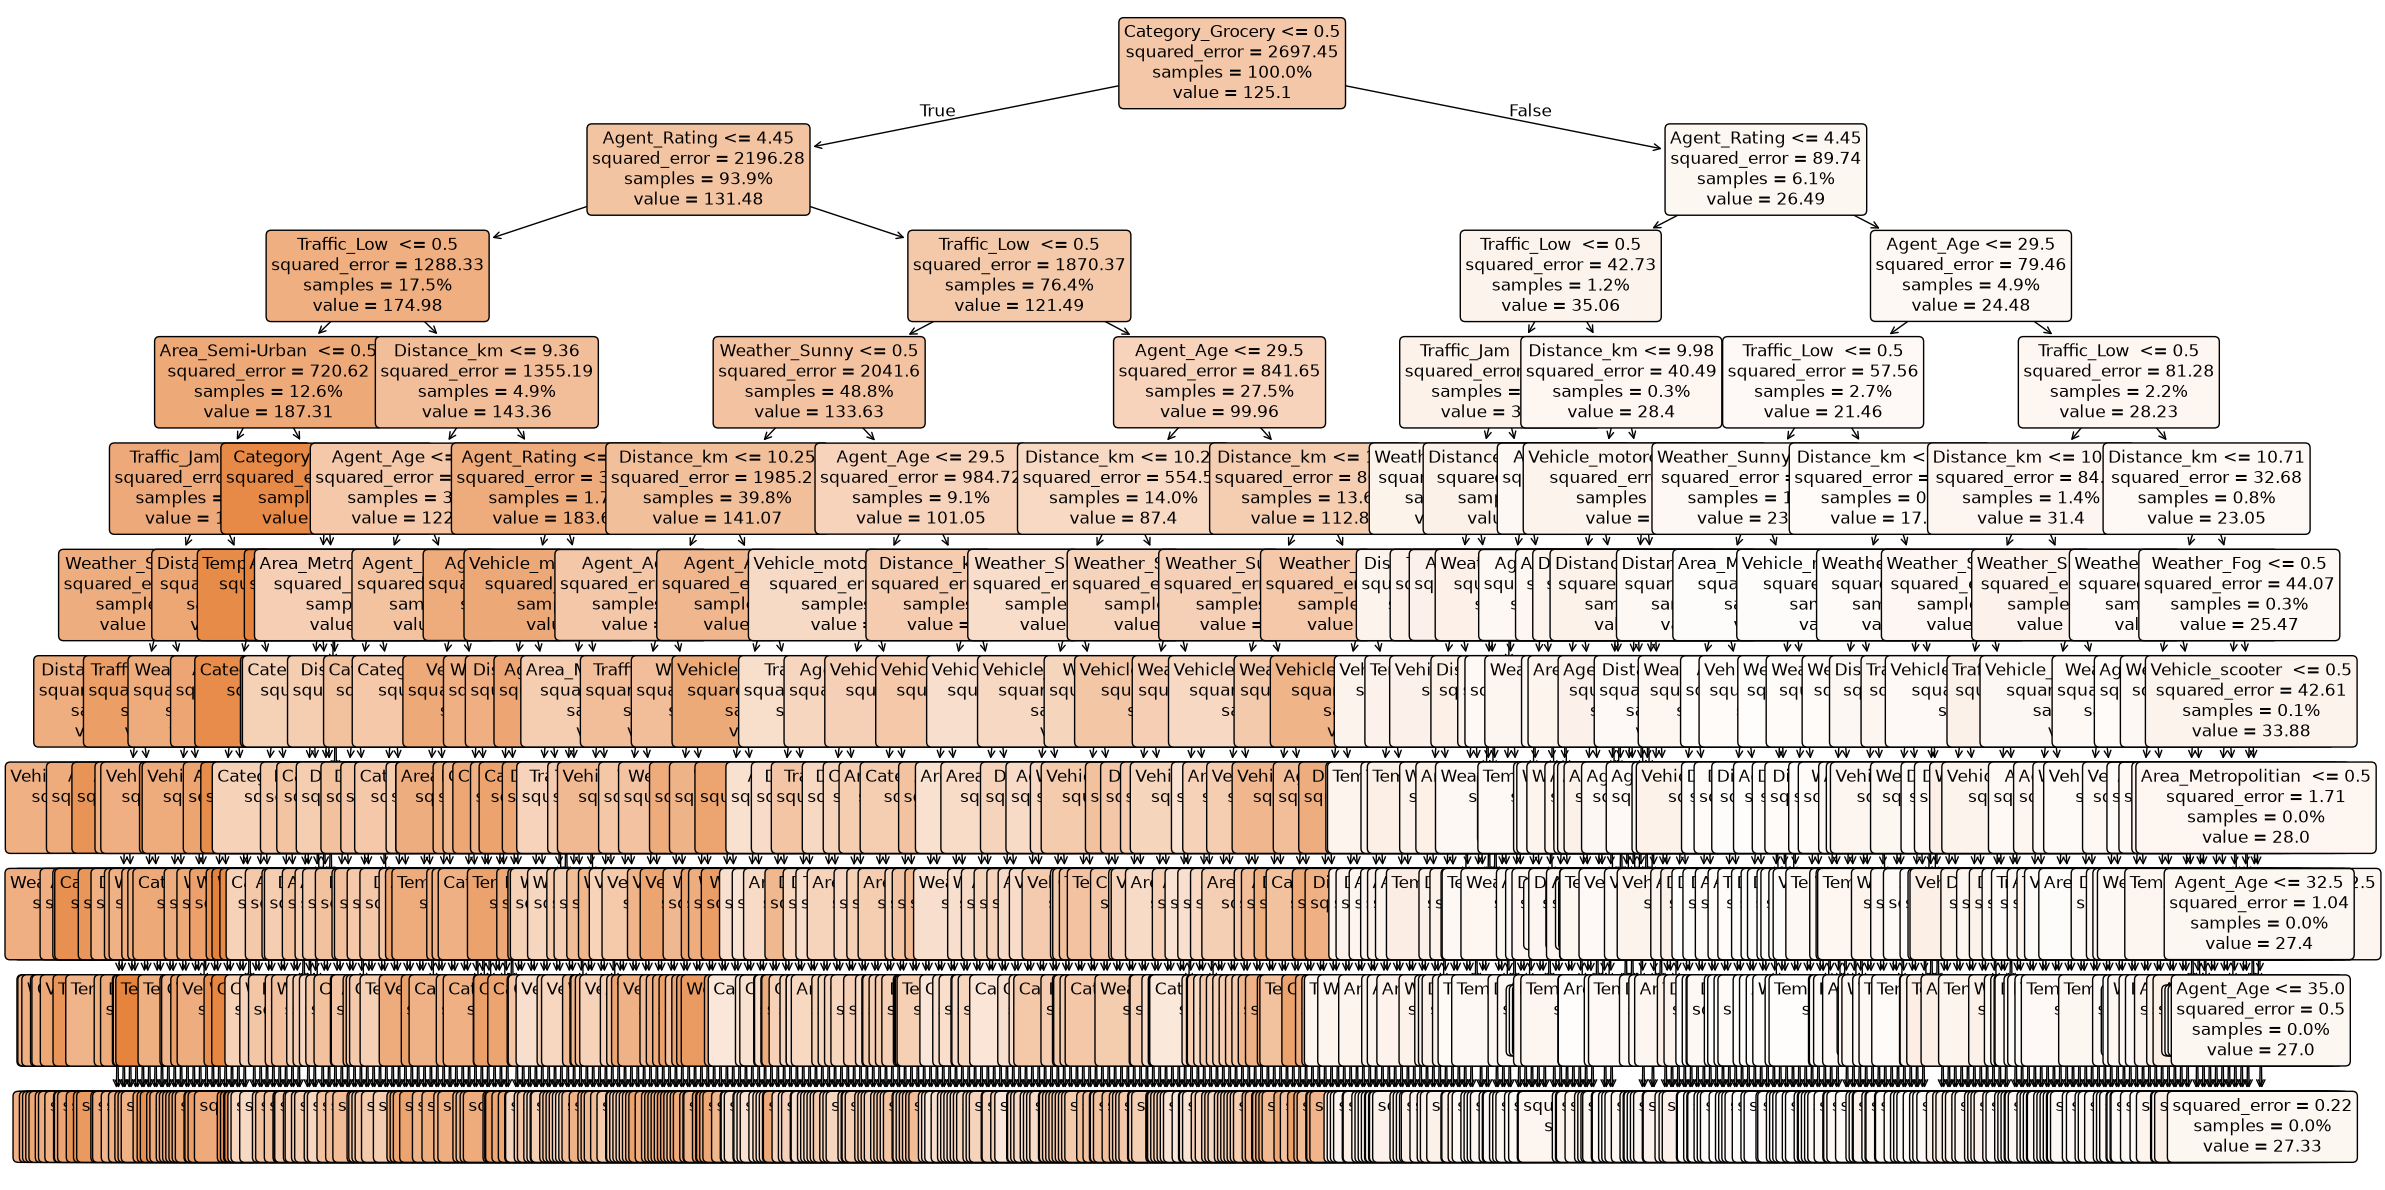

In [47]:
# visualizando a árvore de decisão

plt.figure(figsize=(24, 12))

plot_tree(
    modelo_podado,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=12,
    proportion=True,
    precision=2
)

plt.tight_layout()
plt.show()

# Re-treinando com hiperparametros

In [48]:
grade_parametros = {
    'max_depth': [5, 10, 15, 20],
    'min_samples_leaf': [1, 10, 50, 100],
    'criterion': ['squared_error', 'absolute_error']
}

modelo_grid = DecisionTreeRegressor(random_state=5389)

grid_search = GridSearchCV(
    estimator=modelo_grid,
    param_grid=grade_parametros,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_treino, y_treino)

print(f'Melhores parâmetros encontrados: {grid_search.best_params_}')
print(
    'Melhor RMSE médio na validação cruzada: '
    f'{-grid_search.best_score_:.3f}'
)

Fitting 5 folds for each of 32 candidates, totalling 160 fits
Melhores parâmetros encontrados: {'criterion': 'squared_error', 'max_depth': 10, 'min_samples_leaf': 10}
Melhor RMSE médio na validação cruzada: 22.410


In [50]:
# treinando com os melhores parâmetros encontrados

melhores_parametros = grid_search.best_params_

modelo_otimizado = DecisionTreeRegressor(
    random_state=5389,
    **melhores_parametros
)
modelo_otimizado.fit(X_treino, y_treino)
predicoes_otimizadas = modelo_otimizado.predict(X_teste)

In [51]:
mae_otim = mean_absolute_error(y_teste, predicoes_otimizadas)
rmse_otim = np.sqrt(mean_squared_error(y_teste, predicoes_otimizadas))
r2_otim = r2_score(y_teste, predicoes_otimizadas)

# Métricas no conjunto de treino para verificar overfitting
predicoes_otim_treino = modelo_otimizado.predict(X_treino)
rmse_otim_treino = np.sqrt(
    mean_squared_error(y_treino, predicoes_otim_treino)
)
mae_otim_treino = mean_absolute_error(y_treino, predicoes_otim_treino)
r2_otim_treino = r2_score(y_treino, predicoes_otim_treino)

print('Árvore otimizada — desempenho final')
print('-' * 55)
print(
    f'R²   treino: {r2_otim_treino:.3f}  |  '
    f'R²   teste: {r2_otim:.3f}'
)
print(
    f'RMSE treino: {rmse_otim_treino:.2f}  |  '
    f'RMSE teste: {rmse_otim:.2f}'
)
print(
    f'MAE  treino : {mae_otim_treino:.2f}  |  '
    f'MAE  teste : {mae_otim:.2f}'
)

Árvore otimizada — desempenho final
-------------------------------------------------------
R²   treino: 0.826  |  R²   teste: 0.819
RMSE treino: 21.66  |  RMSE teste: 22.08
MAE  treino : 16.64  |  MAE  teste : 17.13


In [ ]:
# vendo a profundidade e o número de folhas da árvore original e da otimizada

print(modelo.get_depth(), modelo.get_n_leaves())
print(modelo_otimizado.get_depth(), modelo_otimizado.get_n_leaves())


44 25734
10 456


In [ ]:
# vendo as features mais importantes da árvore otimizada

pd.Series(modelo_otimizado.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)


Category_Grocery       0.282350
Agent_Rating           0.189781
Traffic_Low            0.120589
Agent_Age              0.093171
Distance_km            0.089153
Weather_Sunny          0.064423
Weather_Cloudy         0.056962
Weather_Fog            0.041724
Vehicle_motorcycle     0.026351
Traffic_Medium         0.013414
dtype: float64